# 09 · Learning from Reviewer Corrections

**Goal:** show how the system gets better with use, without retraining.

Every entry a reviewer confirms becomes billing history, and three clues read billing history: past narratives, people named in narratives, and each timekeeper's hours by matter. So confirmed entries can improve the next day's decisions right away.

| | What changes | How often |
|---|---|---|
| **Feedback** (`add_confirmed` in `src/pipeline.py`) | billing history: confirmed narratives are embedded and added, new names are learned, hours are added | every day |
| **Retraining** (`src/train.py`) | the models and cutoffs | occasionally |

VAL is replayed in date order, in batches. After each batch, its entries are confirmed, with the answer key standing in for the reviewer, and the next batch is scored with the updated history. TEST and the holdout file aren't used.

**Questions**
1. How much do decisions improve when confirmed entries are added as they come in?
2. How fast does a timekeeper with no history catch up?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

sys.path.insert(0, "../src")
from rules import score, summarize
from pipeline import load_reference, load_entries, mark_true_matters, score_entries, add_confirmed
from evaluate import pair_metrics

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
RESULTS_DIR = Path("../results")
SETTING = "default"
SPLIT = "VAL"
BATCHES = 4                  # VAL is replayed in this many batches, in date order
SKIP_CLIENTS = ["Firm"]      # as in notebooks 00 and 06

SHOW = ["entries", "decided_precision", "straight_through", "review_share", "silent_errors", "top_1"]

## 2. Load data

The saved system from notebook 04, and VAL read from the time-entry file with `load_entries`, sorted by work date and cut into batches.

In [3]:
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
encoder = SentenceTransformer(feature_config["embedding_model"])
ref = load_reference(DATA_PATH, RESULTS_DIR, encoder, SETTING)

entries, answers = load_entries(DATA_PATH, ref, SKIP_CLIENTS)
answers = answers[answers["split"] == SPLIT].reset_index(drop=True)
entries = entries[entries["entry_id"].isin(answers["entry_id"])].copy()
entries["work_date"] = pd.to_datetime(entries["work_date"])
entries = entries.sort_values(["work_date", "entry_id"]).reset_index(drop=True)
bounds = np.linspace(0, len(entries), BATCHES + 1).astype(int)
batches = [entries.iloc[start:end] for start, end in zip(bounds[:-1], bounds[1:])]

assert entries["hours"].notna().all()
pd.DataFrame({"entries": [len(b) for b in batches], "from": [b["work_date"].min().date() for b in batches],
              "to": [b["work_date"].max().date() for b in batches]}, index=range(1, BATCHES + 1)).rename_axis("batch")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,entries,from,to
batch,,,
1,150,2026-07-06,2026-07-28
2,150,2026-07-28,2026-08-21
3,150,2026-08-21,2026-09-11
4,151,2026-09-12,2026-09-30


## 3. What counts as confirmed

After a batch is decided, each entry's final matter goes into history, with the answer key standing in for what a reviewer would confirm. Two kinds of entries are left out, like notebook 02's history:
- **New clients or matters:** there's no matter in Matter Master to add them to yet.
- **Multi-matter entries:** a firm splits them before billing, and the split pieces aren't in the data.

`replay` scores each batch with the history as it stands, then (with `feedback` on) adds that batch's confirmed entries before the next one.

In [4]:
def confirmed(batch):
    key = batch.merge(answers[["entry_id", "key_true_cmid", "key_secondary_cmid"]], on="entry_id")
    key = key[(key["key_true_cmid"] != "NONE") & key["key_secondary_cmid"].isna()]
    return key[["entry_id", "tk_id", "narrative", "hours"]].assign(cmid=key["key_true_cmid"])


def replay(batches, feedback):
    current, rows = ref, []
    for k, batch in enumerate(batches, start=1):
        pairs, _, decisions = score_entries(batch, current)
        pairs = mark_true_matters(pairs, answers)
        rows.append({"batch": k, **summarize(score(decisions, answers)), "top_1": pair_metrics(pairs)["top_1"],
                     "history_entries": len(current["past_cmids"])})
        if feedback:
            current = add_confirmed(current, confirmed(batch))
    return pd.DataFrame(rows).set_index("batch")

## 4. Everyone as usual

VAL in date order, with and without feedback. Batch 1 is the same either way, since nothing has been confirmed yet.

In [5]:
usual = pd.concat({"no feedback": replay(batches, feedback=False), "with feedback": replay(batches, feedback=True)})
usual[SHOW + ["history_entries"]].round(3)

entries  decided_precision  straight_through  \
              batch                                                 
no feedback   1          150              0.971             0.693   
              2          150              0.982             0.753   
              3          150              1.000             0.733   
              4          151              0.957             0.762   
with feedback 1          150              0.971             0.693   
              2          150              0.982             0.727   
              3          150              0.991             0.760   
              4          151              0.952             0.689   

                     review_share  silent_errors  top_1  history_entries  
              batch                                                       
no feedback   1             0.193              3  0.929             2628  
              2             0.140              2  0.923             2628  
              3             0.147              0  0.964             2628  
              4             0.126              4  0.923             2628  
with feedback 1             0.193              3  0.929             2628  
              2             0.153              2  0.923             2759  
              3             0.113              1  0.964             2893  
              4             0.179              5  0.923             3025

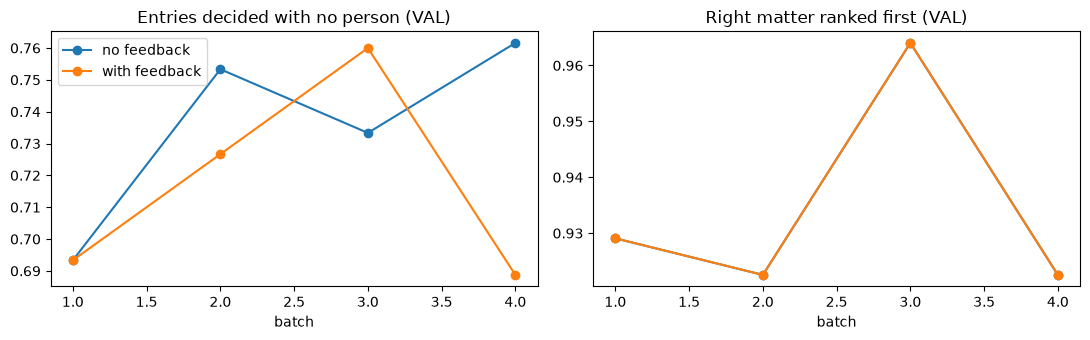

In [6]:
def plot_replay(results, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for name, df in results.groupby(level=0):
        axes[0].plot(df.index.get_level_values(1), df["straight_through"], marker="o", label=name)
        axes[1].plot(df.index.get_level_values(1), df["top_1"], marker="o", label=name)
    axes[0].set(title=f"Entries decided with no person ({title})", xlabel="batch")
    axes[1].set(title=f"Right matter ranked first ({title})", xlabel="batch")
    axes[0].legend()
    plt.tight_layout()
    plt.show()


plot_replay(usual, "VAL")

- **For timekeepers with billing history, feedback changes little.** Top-1 is the same in every batch, and the straight-through rate moves both ways (up 3 points in batch 3, down 7 in batch 4), with 2 more silent errors over batches 2 to 4.
- About 400 confirmed entries are added (2,628 to 3,025 past entries), but these timekeepers and matters are already well covered.
- **Batch 4 shows a limit:** the models were trained on a fixed amount of billing history, so as hours keep growing, the history clues likely drift from what the models learned. That's what retraining (`src/train.py`) is for.

## 5. New timekeepers

The same replay with every VAL timekeeper treated as a new hire: their IDs are changed so they start with no hours in billing history, like the new-timekeeper stress test in notebook 05. Past narratives and people still come from everyone's history.

This is where feedback should matter most, since timekeeper hours are one of the strongest clues and a new hire starts with none.

In [7]:
new_hires = [b.assign(tk_id="NEW-" + b["tk_id"]) for b in batches]
hires = pd.concat({"no feedback": replay(new_hires, feedback=False), "with feedback": replay(new_hires, feedback=True)})
hires[SHOW].round(3)

entries  decided_precision  straight_through  \
              batch                                                 
no feedback   1          150              0.915             0.627   
              2          150              0.989             0.607   
              3          150              0.981             0.687   
              4          151              0.938             0.642   
with feedback 1          150              0.915             0.627   
              2          150              0.990             0.673   
              3          150              0.990             0.693   
              4          151              0.953             0.702   

                     review_share  silent_errors  top_1  
              batch                                      
no feedback   1             0.200              8  0.823  
              2             0.227              1  0.852  
              3             0.193              2  0.878  
              4             0.238              5  0.859  
with feedback 1             0.200              8  0.823  
              2             0.180              1  0.887  
              3             0.167              1  0.935  
              4             0.166              5  0.915

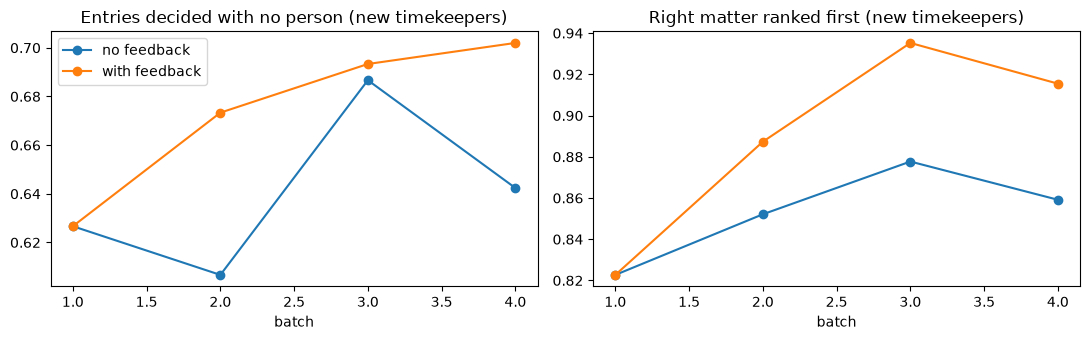

In [8]:
plot_replay(hires, "new timekeepers")

- **Feedback helps new timekeepers right away:** after one batch of about 150 confirmed entries (about three weeks of work), top-1 is 89% vs. 85% with no feedback, and 67% of entries are decided with no person vs. 61%.
- **By batches 3 and 4, new timekeepers rank the right matter first 92% to 94% of the time,** close to everyone else (92% to 96%), vs. 86% to 88% with no feedback.
- **Review drops to about 17% (vs. 19% to 24%) with no more silent errors** (7 vs. 8 over batches 2 to 4).

## 6. Findings

### Results
- **Confirmed entries update billing history the same day, with no retraining.**
- **New timekeepers catch up fast:** within about three weeks of entries, they rank the right matter first 4 to 6 points more often and are decided with no person up to 7 points more often. By batches 3 and 4, they're close to everyone else.
- **For timekeepers with history, feedback adds little,** and the last batch decides fewer entries automatically.

### Why both loops are needed
- **Feedback** fixes thin history, like a new hire, right away.
- **Retraining** keeps the models matched to history that keeps growing. The batch-4 drop is likely the history clues drifting from what the models were trained on.

### Limitations
- The answer key stands in for the reviewer. Real reviewers make mistakes, and a wrong confirmation would add wrong history.
- Multi-matter entries and new clients or matters aren't added.
- VAL has about 600 entries in 4 batches of about 150, so a few entries move each batch by several points.
- Only about three months of work dates are replayed.

### Next steps
- Build the confirm step into the review screen, so each confirmation calls `add_confirmed`.
- Retrain on a schedule with `src/train.py`, and watch for the drift seen in batch 4.